In [630]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import(
mean_squared_error,
mean_absolute_percentage_error,
mean_absolute_error,
r2_score)
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM,Dense,Dropout
from tensorflow.keras.callbacks import EarlyStopping
import tensorflow as tf
import random

random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)

In [631]:
df=pd.read_csv(r"C:\Users\Pc\Documents\pfa_stage_project\data\processed\model_data\final_dataset.csv")
df.head()

,Date,KCL,Phosphate,DAP,Gas_EUR,Brent
0,1967-01-01,25.5,12.0,68.5,0.456647,1.33
1,1967-02-01,25.5,12.0,68.5,0.456647,1.33
2,1967-03-01,25.5,12.0,68.5,0.456647,1.33
3,1967-04-01,25.5,12.0,68.5,0.456647,1.33
4,1967-05-01,25.5,12.0,68.5,0.456647,1.33


In [632]:
df.describe()

,KCL,Phosphate,DAP,Gas_EUR,Brent
count,707.000000,707.000000,707.000000,707.000000,707.000000
mean,177.519823,70.528798,260.705205,5.410660,38.641693
std,168.897409,72.629403,184.539741,6.357615,32.213264
min,22.000000,11.000000,54.000000,0.447218,1.210000
25%,75.500000,32.000000,146.000000,2.360000,15.020000
50%,112.500000,44.000000,186.125000,3.650000,27.809999
75%,240.190000,90.000000,357.175000,7.142875,62.322368
max,1202.000000,450.000000,1075.750000,70.043640,133.873043


In [633]:
df["Date"]=pd.to_datetime(df["Date"])
df=df.sort_values("Date")
df.head()

,Date,KCL,Phosphate,DAP,Gas_EUR,Brent
0,1967-01-01,25.5,12.0,68.5,0.456647,1.33
1,1967-02-01,25.5,12.0,68.5,0.456647,1.33
2,1967-03-01,25.5,12.0,68.5,0.456647,1.33
3,1967-04-01,25.5,12.0,68.5,0.456647,1.33
4,1967-05-01,25.5,12.0,68.5,0.456647,1.33


In [634]:
features=[
    "KCL",
    "Phosphate",
    "DAP",
    "Gas_EUR",
    "Brent"
]

data=df[features]

In [635]:
#gestion des valeurs manquantes
data=data.interpolate()
data=data.dropna()
data.shape

(707, 5)

In [636]:
#creation des sequences
#sert a transformer la serie en sequences que le lstm peut apprendre
def create_dataset(dataset,time_step=12):
    X,y=[],[]

    for i in range(len(dataset)-time_step):
        X.append(dataset[i:i+time_step])#prend 12 observations consecutives
        y.append(dataset[i+time_step,0])#prend uniquement la premiere colonne ,et prend la valeur située juste apres les 12 mois

    return np.array(X),np.array(y)
time_step=12#(le model va utiliser les 12 mois precedants pour predire le mois suivant)

In [637]:
#separation temporelle (70% train, 10%validation, 20% test)
train_size = int(len(data) * 0.7)
val_size = int(len(data) * 0.1)

train_data = data.iloc[:train_size]
val_data = data.iloc[train_size:train_size + val_size]
test_data = data.iloc[train_size+val_size:]

#scaler
scaler = MinMaxScaler()

#scaler seulement sur le train
train_scaled = scaler.fit_transform(train_data)
#transformer le test et le val
val_scaled = scaler.transform(val_data)
test_scaled = scaler.transform(test_data)


In [638]:
X_train,y_train=create_dataset(train_scaled,time_step)
#validation
val_input = pd.concat([
    train_data.tail(time_step),
    val_data
])
val_scaled = scaler.transform(val_input)
X_val, y_val = create_dataset(val_scaled, time_step)

#test
test_input = pd.concat([
    val_data.tail(time_step),
    test_data
])

test_scaled = scaler.transform(test_input)
X_test,y_test=create_dataset(test_scaled,time_step)

In [639]:
print(X_train.shape)
print(y_train.shape)
print(X_val.shape)
print(y_val.shape)
print(X_test.shape)
print(y_test.shape)

(482, 12, 5)
(482,)
(70, 12, 5)
(70,)
(143, 12, 5)
(143,)


In [ ]:
#model lstm
model=Sequential()

#couche principale
model.add(
LSTM(units=128,#128 neurones memorisant les relations temporelles 
activation='tanh',
input_shape=(X_train.shape[1],X_train.shape[2])
#input shape vaut (12,5)
)
)


#Dense(32) cette couche apprend les relations supplementaires apres le lstm 
#Dense(1) une seule sortie
 
model.add(Dropout(0.1))

model.add(Dense(32,activation='relu'))
model.add(Dense(1))


early_stop = EarlyStopping(
    monitor="val_loss", #on surveille la perte sur le jeu de validation
    patience=10, #on attend 10 epochs sans amelioration avant d arreter
    restore_best_weights=True
) 




c:\Users\Pc\Downloads\anaconda\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [641]:
#compilation
model.compile(optimizer='adam',loss='mse')
model.summary()

Model: "sequential_37"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_40 (LSTM)                  │ (None, 128)            │        68,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_36 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_64 (Dense)                │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_65 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 72,769 (284.25 KB)

 Trainable params: 72,769 (284.25 KB)

 Non-trainable params: 0 (0.00 B)

In [642]:
#entrainement
history=model.fit(

X_train,y_train,epochs=100,
batch_size=8,
validation_data=(X_val,y_val),
callbacks=[early_stop],
verbose=1 #affiche la progression
)

Epoch 1/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.0085 - val_loss: 0.2181
Epoch 2/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0017 - val_loss: 0.3049
Epoch 3/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0013 - val_loss: 0.2481
Epoch 4/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0012 - val_loss: 0.2418
Epoch 5/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 9.9813e-04 - val_loss: 0.2382
Epoch 6/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0011 - val_loss: 0.2542
Epoch 7/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0012 - val_loss: 0.2510
Epoch 8/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0013 - val_loss: 0.2455
Epoch 9/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 8.9931e-04 - val_loss: 0.2264
Epoch 10/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 9.4263e-04 - val_loss: 0.1840
Epoch 11/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 7.6475e-04 - val_loss: 0.1859
Epoch 12/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 1s 

In [643]:
y_pred=model.predict(X_test)
print(y_pred.shape)

5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 59ms/step
(143, 1)


In [644]:
#on cree un tableau de 5 colonnes dont la premiere est kcl predite et les autres remplis de 0
pred_temp = np.zeros((len(y_pred), len(features)))

In [645]:
pred_temp[:,0] = y_pred.flatten() #car le scaller a ete entraine sur 5 colonnes
pred_inverse = scaler.inverse_transform(pred_temp)#retour a l echelle originale

In [646]:
y_pred_final = pred_inverse[:,0]#on prend seulement la premiere colonne

In [647]:
y_test_temp = np.zeros((len(y_test), len(features)))
y_test_temp[:,0] = y_test #on fait la meme chose mais cette fois avec y_test
real_inverse = scaler.inverse_transform(y_test_temp)
y_test_final = real_inverse[:,0]

In [648]:
rmse = np.sqrt(mean_squared_error(y_test_final, y_pred_final))

mae = mean_absolute_error(y_test_final, y_pred_final)

mape = mean_absolute_percentage_error(y_test_final, y_pred_final)

r2 = r2_score(y_test_final, y_pred_final)

print(f"RMSE : {rmse:.3f}")
print(f"MAE  : {mae:.3f}")
print(f"MAPE : {mape*100:.2f}%")
print(f"R²   : {r2:.4f}")


RMSE : 62.246
MAE  : 34.439
MAPE : 8.06%
R²   : 0.9035


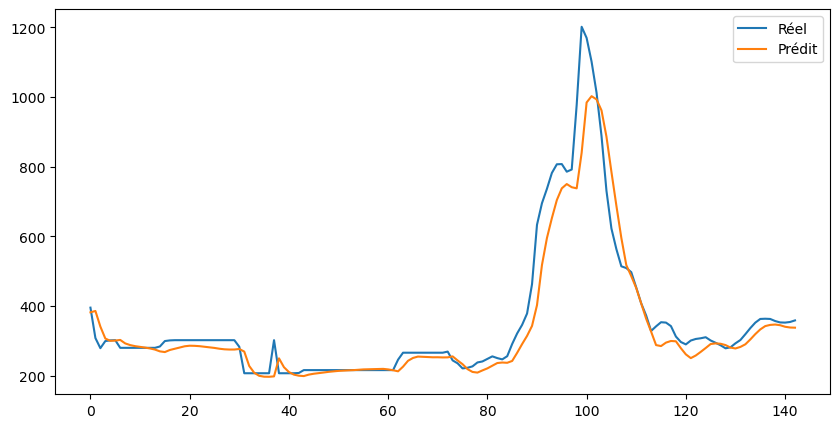

In [649]:
plt.figure(figsize=(10,5))
plt.plot(y_test_final,label="Réel")
plt.plot(y_pred_final,label="Prédit")
plt.legend()
# plt.savefig("prediction.png")
plt.show()

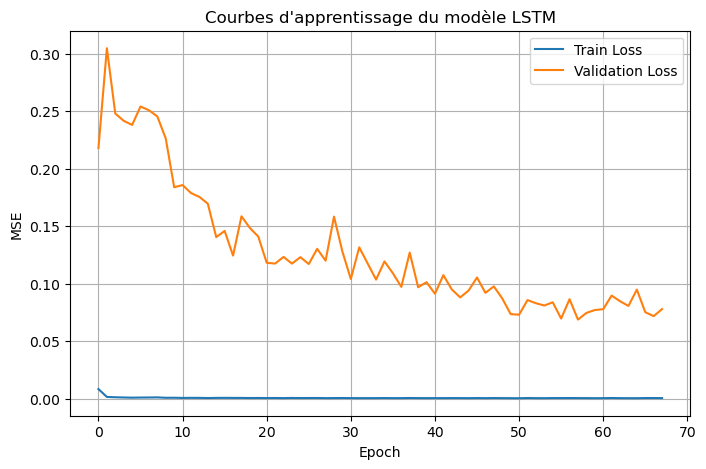

In [650]:
plt.figure(figsize=(8,5))
plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Courbes d'apprentissage du modèle LSTM")
plt.legend()
plt.grid(True)

# plt.savefig("loss.png")
plt.show()